# Dana's Bakery — deterministic LangGraph order processing

This notebook implements the repository's authoritative `prompt.md`. Run **Runtime → Run all** in a fresh Google Colab Python runtime. No secrets, API keys, LLMs, datasets or persistent storage are needed.

The fixed stock snapshot is checked independently for each order, with no partial fulfillment. At most two alternatives follow `babka → rugelach → sourdough → challah`. Avi's final policy supersedes the earlier discount: **15% off baked goods only when subtotal > 150 ILS and day is not Friday**. Jerusalem delivery costs 20 ILS; other cities require pickup.

The specification permits only `accepted` and `rejected`. It defines no cancellation request or separate cancelled status; orders that cannot be fulfilled are rejected. We do not invent a cancellation branch.


## 1. Install
`%pip` installs into the active notebook kernel. LangGraph 1.x is supported. The graph diagram uses LangGraph's default Mermaid rendering service, so drawing requires internet access (as does this installation). Order processing itself is local deterministic Python.

In [1]:
%pip -q install "langgraph>=1.0,<2"


[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


## 2. Imports, menu and fixed inventory

In [2]:
from typing import TypedDict, Annotated, Literal
from collections.abc import Mapping
import operator
from pprint import pprint
from importlib.metadata import version
from IPython.display import Image, display
from langgraph.graph import StateGraph, START, END

PRICES = {"challah": 18, "babka": 45, "rugelach": 30, "sourdough": 25}
STOCK = {"challah": 10, "babka": 0, "rugelach": 3, "sourdough": 4}
SEQUENCE = ("babka", "rugelach", "sourdough", "challah")
DAYS = {day.lower(): day for day in (
    "Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"
)}
RESULT_KEYS = ("status", "item", "delivery", "total", "message", "steps")
print("LangGraph", version("langgraph"))

LangGraph 1.2.20


## 3. State and eight nodes
Each node returns an update dictionary and its own one-element step list. The `operator.add` reducer concatenates these lists, preserving repeated stock checks. Nodes do not mutate the input state.

In [3]:
class State(TypedDict, total=False):
    item: str
    quantity: int
    day: str
    city: str
    original_item: str
    attempts: int
    valid: bool
    in_stock: bool
    reason: str
    subtotal: float
    discount: float
    delivery_fee: float
    outside_city: bool
    status: Literal["accepted", "rejected"]
    delivery: Literal["pickup", "delivery"]
    total: float
    message: str
    steps: Annotated[list[str], operator.add]


def normalize(value):
    return " ".join(value.split()).lower() if isinstance(value, str) else ""


def validate_order(state: State):
    item = normalize(state.get("item"))
    day_key = normalize(state.get("day"))
    city_value = state.get("city", "")
    quantity = state.get("quantity")
    errors = []
    if item not in PRICES:
        errors.append("Please choose challah, babka, rugelach or sourdough; croissant is discontinued.")
    if type(quantity) is not int or quantity <= 0:
        errors.append("Please provide a positive whole-number quantity (not a boolean).")
    if day_key not in DAYS:
        errors.append("Please provide a recognized English weekday, Monday through Sunday.")
    if not isinstance(city_value, str):
        errors.append("Please provide the city as text, or leave it empty for pickup.")
    return {"item": item, "original_item": item, "day": DAYS.get(day_key, day_key),
            "city": normalize(city_value), "attempts": 0, "valid": not errors,
            "reason": " ".join(errors), "steps": ["validate_order"]}


def check_stock(state: State):
    return {"in_stock": STOCK[state["item"]] >= state["quantity"],
            "steps": ["check_stock"]}


def suggest_alternative(state: State):
    next_item = SEQUENCE[SEQUENCE.index(state["item"]) + 1]
    return {"item": next_item, "attempts": state["attempts"] + 1,
            "steps": ["suggest_alternative"]}


def calculate_discount(state: State):
    subtotal = state["quantity"] * PRICES[state["item"]]
    discount = round(subtotal * 0.15, 2) if subtotal > 150 and state["day"] != "Friday" else 0.0
    return {"subtotal": float(subtotal), "discount": discount,
            "steps": ["calculate_discount"]}


def handle_delivery(state: State):
    delivery = "delivery" if state["city"] == "jerusalem" else "pickup"
    fee = 20.0 if delivery == "delivery" else 0.0
    return {"delivery": delivery, "delivery_fee": fee,
            "outside_city": bool(state["city"]) and delivery == "pickup",
            "total": round(state["subtotal"] - state["discount"] + fee, 2),
            "steps": ["handle_delivery"]}


def accept_order(state: State):
    return {"status": "accepted", "steps": ["accept_order"]}


def reject_order(state: State):
    reason = state.get("reason") or (
        f"We cannot supply all {state['quantity']} units of {state['original_item']}. "
        + ("The two allowed alternatives also have insufficient stock."
           if state["attempts"] == 2 else "No further alternative is available.")
    )
    return {"status": "rejected", "total": 0.0, "delivery": "pickup",
            "reason": reason, "steps": ["reject_order"]}


def create_message(state: State):
    if state["status"] == "rejected":
        message = f"Sorry, we could not accept your order. {state['reason']} No charge was made."
    else:
        parts = [f"Thank you! Your order for {state['quantity']} × {state['item']} is accepted."]
        if state["item"] != state["original_item"]:
            parts.append(f"We substituted {state['item']} for {state['original_item']} because of insufficient stock, keeping your quantity unchanged.")
        if state["discount"]:
            parts.append(f"Your 15% baked-goods discount saves {state['discount']:.2f} ILS.")
        if state["outside_city"]:
            parts.append("Delivery outside Jerusalem is unavailable; pickup is required.")
        elif state["delivery"] == "delivery":
            parts.append("Delivery to Jerusalem costs 20.00 ILS.")
        else:
            parts.append("Your order is for free pickup.")
        parts.append(f"Total: {state['total']:.2f} ILS.")
        message = " ".join(parts)
    return {"message": message, "steps": ["create_message"]}

## 4. Explicit routing and graph construction
An insufficient-stock route offers another product only when fewer than two alternatives have been tried and the sequence has a successor. Thus at most three stock checks occur; the loop cannot continue indefinitely.

In [4]:
def route_validation(state: State) -> Literal["check_stock", "reject_order"]:
    return "check_stock" if state["valid"] else "reject_order"


def route_stock(state: State) -> Literal["calculate_discount", "suggest_alternative", "reject_order"]:
    if state["in_stock"]:
        return "calculate_discount"
    if state["attempts"] < 2 and state["item"] != SEQUENCE[-1]:
        return "suggest_alternative"
    return "reject_order"


builder = StateGraph(State)
for node in (validate_order, check_stock, suggest_alternative, calculate_discount,
             handle_delivery, accept_order, reject_order, create_message):
    builder.add_node(node.__name__, node)
builder.add_edge(START, "validate_order")
builder.add_conditional_edges("validate_order", route_validation,
                             {name: name for name in ("check_stock", "reject_order")})
builder.add_conditional_edges("check_stock", route_stock,
                             {name: name for name in ("calculate_discount", "suggest_alternative", "reject_order")})
builder.add_edge("suggest_alternative", "check_stock")
builder.add_edge("calculate_discount", "handle_delivery")
builder.add_edge("handle_delivery", "accept_order")
builder.add_edge("accept_order", "create_message")
builder.add_edge("reject_order", "create_message")
builder.add_edge("create_message", END)
graph = builder.compile()

## 5. Inline graph diagram
This renders a PNG with `draw_mermaid_png()`. A rendering/network error should be resolved and this cell rerun; it is not silently hidden.

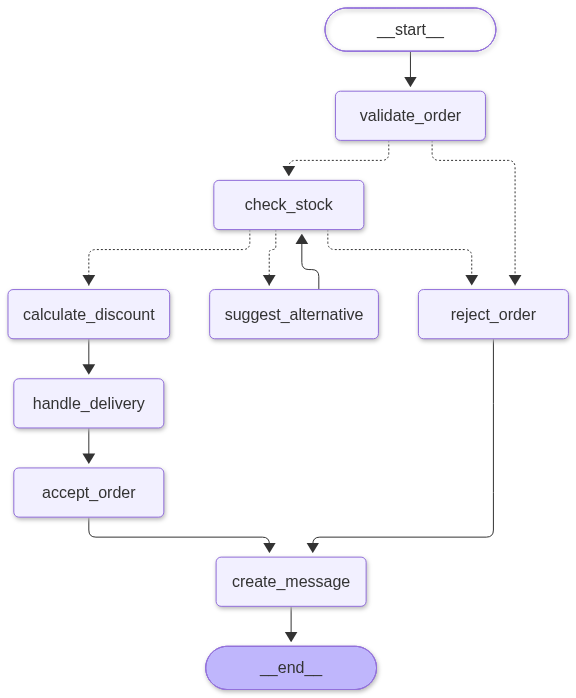

In [5]:
display(Image(graph.get_graph().draw_mermaid_png()))

## 6. Exact sample invocation

In [6]:
result = graph.invoke({
    "item": "babka",
    "quantity": 2,
    "day": "Thursday",
    "city": "Jerusalem",
})
pprint(result)

{'attempts': 1,
 'city': 'jerusalem',
 'day': 'Thursday',
 'delivery': 'delivery',
 'delivery_fee': 20.0,
 'discount': 0.0,
 'in_stock': True,
 'item': 'rugelach',
 'message': 'Thank you! Your order for 2 × rugelach is accepted. We '
            'substituted rugelach for babka because of insufficient stock, '
            'keeping your quantity unchanged. Delivery to Jerusalem costs '
            '20.00 ILS. Total: 80.00 ILS.',
 'original_item': 'babka',
 'outside_city': False,
 'quantity': 2,
 'reason': '',
 'status': 'accepted',
 'steps': ['validate_order',
           'check_stock',
           'suggest_alternative',
           'check_stock',
           'calculate_discount',
           'handle_delivery',
           'accept_order',
           'create_message'],
 'subtotal': 60.0,
 'total': 80.0,
 'valid': True}


## 7. Required tests and exact path assertions
Each tuple below specifies the input and expected `(status, item, delivery, total)`. Every order invokes the same compiled graph with a fresh input. Assertions check every node in chronological order and all six result fields. Required cases 1–12 follow `prompt.md`.

In [7]:
def order(item="challah", quantity=2, day="Monday", city=""):
    return dict(item=item, quantity=quantity, day=day, city=city)


def expected_steps(status, suggestions=0, invalid=False):
    path = ["validate_order"]
    if not invalid:
        path += ["check_stock"]
        for _ in range(suggestions):
            path += ["suggest_alternative", "check_stock"]
    if status == "accepted":
        path += ["calculate_discount", "handle_delivery", "accept_order"]
    else:
        path += ["reject_order"]
    return path + ["create_message"]


# name, input, expected four fields, number of alternatives, invalid input
cases = [
    ("1 pickup", order(), ("accepted", "challah", "pickup", 36.0), 0, False),
    ("2 first alternative", order("babka", 2, "Thursday", "Jerusalem"), ("accepted", "rugelach", "delivery", 80.0), 1, False),
    ("3 second alternative", order("babka", 4, "Tuesday"), ("accepted", "sourdough", "pickup", 100.0), 2, False),
    ("4 exhausted alternatives", order("babka", 5, "Tuesday", "Jerusalem"), ("rejected", "sourdough", "pickup", 0.0), 2, False),
    ("5 invalid item", order("pizza", 1, city="Jerusalem"), ("rejected", "pizza", "pickup", 0.0), 0, True),
    ("6 bad quantity", order(quantity=-2), ("rejected", "challah", "pickup", 0.0), 0, True),
    ("7 outside city", order(day="Wednesday", city="Haifa"), ("accepted", "challah", "pickup", 36.0), 0, False),
    ("8 Avi discount", order(quantity=10, day="Thursday", city="Jerusalem"), ("accepted", "challah", "delivery", 173.0), 0, False),
    ("9 Friday", order(quantity=10, day="Friday", city="Jerusalem"), ("accepted", "challah", "delivery", 200.0), 0, False),
    ("10 no successor", order(quantity=11, day="Tuesday"), ("rejected", "challah", "pickup", 0.0), 0, False),
    ("11 discontinued", order("croissant", 1, city="Jerusalem"), ("rejected", "croissant", "pickup", 0.0), 0, True),
    ("12 unrecognized day", order(day="Notaday"), ("rejected", "challah", "pickup", 0.0), 0, True),
]


def check_case(case):
    name, inputs, expected, suggestions, invalid = case
    actual = graph.invoke(inputs)
    assert all(key in actual for key in RESULT_KEYS), name
    assert tuple(actual[key] for key in RESULT_KEYS[:4]) == expected, (name, actual)
    assert actual["steps"] == expected_steps(expected[0], suggestions, invalid), (name, actual)
    assert isinstance(actual["message"], str) and actual["message"], name
    assert actual["attempts"] <= 2, name
    print(name)
    pprint({key: actual[key] for key in RESULT_KEYS})
    return actual


results = [check_case(case) for case in cases]
assert "substituted rugelach for babka" in results[1]["message"]
assert "substituted sourdough for babka" in results[2]["message"]
assert "two allowed alternatives" in results[3]["message"]
assert "Delivery outside Jerusalem is unavailable; pickup is required" in results[6]["message"]
assert results[7]["discount"] == 27.0 and results[7]["delivery_fee"] == 20.0
assert results[8]["discount"] == 0.0
print("All 12 required cases passed.")

1 pickup
{'delivery': 'pickup',
 'item': 'challah',
 'message': 'Thank you! Your order for 2 × challah is accepted. Your order is '
            'for free pickup. Total: 36.00 ILS.',
 'status': 'accepted',
 'steps': ['validate_order',
           'check_stock',
           'calculate_discount',
           'handle_delivery',
           'accept_order',
           'create_message'],
 'total': 36.0}
2 first alternative
{'delivery': 'delivery',
 'item': 'rugelach',
 'message': 'Thank you! Your order for 2 × rugelach is accepted. We '
            'substituted rugelach for babka because of insufficient stock, '
            'keeping your quantity unchanged. Delivery to Jerusalem costs '
            '20.00 ILS. Total: 80.00 ILS.',
 'status': 'accepted',
 'steps': ['validate_order',
           'check_stock',
           'suggest_alternative',
           'check_stock',
           'calculate_discount',
           'handle_delivery',
           'accept_order',
           'create_message'],
 'total': 80.

### Additional validation, sequence and boundary checks
The menu has no fulfillable order with subtotal exactly 150 ILS. Test the discount node directly at that boundary without altering the production menu or stock. Additional independent orders exercise every substitution suffix and malformed input category.

In [8]:
extras = [
    ("normalization", order("  ChAlLaH  ", 2, " mOnDaY ", " jErUsAlEm "), ("accepted", "challah", "delivery", 56.0), 0, False),
    ("whitespace pickup", order(city="  \t "), ("accepted", "challah", "pickup", 36.0), 0, False),
    ("stock equality", order("rugelach", 3), ("accepted", "rugelach", "pickup", 90.0), 0, False),
    ("rugelach to challah", order("rugelach", 5), ("accepted", "challah", "pickup", 90.0), 2, False),
    ("sourdough to challah", order("sourdough", 5), ("accepted", "challah", "pickup", 90.0), 1, False),
    ("sequence ends after one", order("sourdough", 11), ("rejected", "challah", "pickup", 0.0), 1, False),
    ("sequence ends after two", order("rugelach", 11), ("rejected", "challah", "pickup", 0.0), 2, False),
    ("empty input", {}, ("rejected", "", "pickup", 0.0), 0, True),
]
for quantity in (True, False, 0, 1.5, "2", None):
    extras.append((f"malformed quantity {quantity!r}", order(quantity=quantity),
                   ("rejected", "challah", "pickup", 0.0), 0, True))
for field, value in (("day", None), ("item", 123), ("city", None), ("day", "")):
    data = order()
    data[field] = value
    extras.append((f"malformed {field}: {value!r}", data,
                   ("rejected", "" if field == "item" else "challah", "pickup", 0.0), 0, True))
for field in ("day", "quantity", "item"):
    data = order()
    del data[field]
    extras.append((f"missing {field}", data,
                   ("rejected", "" if field == "item" else "challah", "pickup", 0.0), 0, True))
extra_results = [check_case(case) for case in extras]
assert calculate_discount({"item": "rugelach", "quantity": 5, "day": "Thursday"})["discount"] == 0.0
assert calculate_discount({"item": "sourdough", "quantity": 7, "day": "Thursday"})["discount"] == 26.25
assert calculate_discount({"item": "sourdough", "quantity": 7, "day": "Friday"})["discount"] == 0.0
for day in DAYS.values():
    assert graph.invoke(order(day=day))["status"] == "accepted"
assert graph.invoke(order(quantity=10))["total"] == 153.0
assert graph.invoke(order(quantity=10))["total"] == 153.0  # no stock depletion
assert STOCK == {"challah": 10, "babka": 0, "rugelach": 3, "sourdough": 4}

# Verify all actual graph edges were exercised, including START and END.
observed_edges = set()
for actual in results + extra_results:
    path = [START] + actual["steps"] + [END]
    observed_edges.update(zip(path, path[1:]))
required_edges = {(edge.source, edge.target) for edge in graph.get_graph().edges}
assert required_edges <= observed_edges, required_edges - observed_edges
print(f"Passed {len(cases) + len(extras)} order cases, pricing boundaries, all weekdays, repeatability, and all {len(required_edges)} graph edges.")

normalization
{'delivery': 'delivery',
 'item': 'challah',
 'message': 'Thank you! Your order for 2 × challah is accepted. Delivery to '
            'Jerusalem costs 20.00 ILS. Total: 56.00 ILS.',
 'status': 'accepted',
 'steps': ['validate_order',
           'check_stock',
           'calculate_discount',
           'handle_delivery',
           'accept_order',
           'create_message'],
 'total': 56.0}
whitespace pickup
{'delivery': 'pickup',
 'item': 'challah',
 'message': 'Thank you! Your order for 2 × challah is accepted. Your order is '
            'for free pickup. Total: 36.00 ILS.',
 'status': 'accepted',
 'steps': ['validate_order',
           'check_stock',
           'calculate_discount',
           'handle_delivery',
           'accept_order',
           'create_message'],
 'total': 36.0}
stock equality
{'delivery': 'pickup',
 'item': 'rugelach',
 'message': 'Thank you! Your order for 3 × rugelach is accepted. Your order is '
            'for free pickup. Total: 90.00 I

## 8. Implementation conventions and verification scope
- `steps: Annotated[list[str], operator.add]` accumulates one entry per node execution; routers are not nodes. Fresh invocation inputs omit `steps`, so traces start empty. The exact-path tests verify order, loop repetitions and early rejection.
- Rejected orders keep the last attempted canonical item (or normalized invalid input; an absent/non-text item becomes `""`), use pickup and total `0.0`, and explain that no charge occurred. No item was sold.
- Missing city defaults to pickup. Missing required item, quantity or day and non-text city values produce friendly rejections. The public invocation contract is an order dictionary; LangGraph itself handles non-dictionary invocation errors outside this contract.
- Normalization strips/collapses whitespace and normalizes case. State may include internal diagnostic fields beyond the six required output keys. Tests display the six public fields.
- Pricing uses the actual substitute's price. Amounts are rounded to two decimal places. Inventory constants are never decremented.
- This notebook contains all twelve specified orders, additional malformed inputs and boundaries, and an assertion that all rendered graph edges were visited. Python assertions are intended to run with normal notebook settings (no optimization).
- The saved cell outputs document execution in the development Python kernel. A hosted Google Colab session has not been used for verification; rerun all cells there to confirm its installation and diagram network access.
